# 34 — Other architectures: ResNet-1D, TCN, 2-D CNN on spectrograms, graph network on time-frequency pixels

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 26 and 50. Four more detectors are trained with the recipe of notebook 07 (fresh injections of the three morphologies at every epoch, binary cross-entropy, AdamW + cosine schedule, best validation loss restored; 12 epochs, one seed each) and evaluated like all others (thresholds from the validation noise, ρ₅₀ over sine-Gaussian, pulse and chirp at FAP 10⁻² and 10⁻³, bootstrap errors, same test injections):

* **ResNet-1D** (stem + 4 residual stages with down-sampling, global max pooling);
* **TCN** (stack of residual dilated convolutions, dilation 1 … 32);
* **2-D CNN** on the log-spectrogram (STFT of 64 samples, 56 overlap: 33 frequencies × 121 frames);
* **Graph network** (EdgeConv) on the 64 time-frequency pixels of largest power, connected to their 8 nearest neighbours in (t, f) — the idea behind the clustering of coherent WaveBurst.

**What it does not do.** One seed per architecture (seed scatter of the CNN at FAP 10⁻² is ≈0.4, notebook 30: differences of a few tenths are not significant); 12 epochs; no tuning of any of them; the reference is the project CNN with fresh injections (4.31 ± 0.40 over five seeds, 5.67 at FAP 10⁻³).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import spectrogram
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
CH, data, S1, DS = sm.load_data(); TEST = sm.make_test_sets(data, S1); SNRS = sm.SNRS; MORPHS = g.MORPHS
noise_tr, S1_tr, noise_va, S1_va = DS["train"]["noise"], S1["train"], DS["val"]["noise"], S1["val"]
def spec(v):
    f, t, P = spectrogram(np.clip(v, -12, 12), fs=g.FS, nperseg=64, noverlap=56, window="hann", axis=-1); return np.log10(P + 1e-3).astype(np.float32)        # (n, 33, 121)
SPE = spec(noise_va[:2]); print("spectrogram shape:", SPE.shape[1:])
NN = 64; KNN = 8
def graph(v):
    # the NN pixels of largest log-power in the band 30-500 Hz -> node features (t, f, logP, logP - local median); returns (n, NN, 4)
    P = spec(v); f = np.fft.rfftfreq(64, 1 / g.FS); band = (f >= 30) & (f <= 500); P = P[:, band, :]; n, nf, nt = P.shape
    flat = P.reshape(n, -1); idx = np.argpartition(-flat, NN, axis=1)[:, :NN]; val = np.take_along_axis(flat, idx, 1); fi, ti = idx // nt, idx % nt
    med = np.median(flat, axis=1, keepdims=True); return np.stack([ti / nt, fi / nf, (val - med) / 2, val / 2 - 0.5], -1).astype(np.float32)

spectrogram shape: (33, 121)


## Architectures

In [2]:
def res_block(x, ch, stride):
    s = x; y = L.BatchNormalization()(x); y = L.ReLU()(y); y = L.Conv1D(ch, 9, strides=stride, padding="same")(y); y = L.BatchNormalization()(y); y = L.ReLU()(y); y = L.Conv1D(ch, 9, padding="same")(y)
    if stride > 1 or s.shape[-1] != ch: s = L.Conv1D(ch, 1, strides=stride)(s)
    return L.Add()([s, y])
def build_resnet(seed=0):
    tf.keras.utils.set_random_seed(seed); i = L.Input((g.NWIN, 1)); x = L.Conv1D(16, 15, padding="same")(i)
    for ch, st in ((16, 2), (32, 2), (32, 2), (64, 2)): x = res_block(x, ch, st)
    x = L.ReLU()(L.BatchNormalization()(x)); x = L.GlobalMaxPooling1D()(x); x = L.Dropout(0.2)(L.Dense(32, activation="relu")(x)); return keras.Model(i, L.Dense(1)(x))
def build_tcn(seed=0):
    tf.keras.utils.set_random_seed(seed); i = L.Input((g.NWIN, 1)); x = L.Conv1D(32, 1)(i)
    for d in (1, 2, 4, 8, 16, 32):
        y = L.Conv1D(32, 5, dilation_rate=d, padding="same")(L.ReLU()(L.BatchNormalization()(x))); y = L.Conv1D(32, 1)(L.ReLU()(y)); x = L.Add()([x, y])
    x = L.GlobalMaxPooling1D()(L.ReLU()(L.BatchNormalization()(x))); x = L.Dropout(0.2)(L.Dense(32, activation="relu")(x)); return keras.Model(i, L.Dense(1)(x))
def build_cnn2d(seed=0):
    tf.keras.utils.set_random_seed(seed); i = L.Input(SPE.shape[1:] + (1,)); x = i
    for ch in (16, 32, 64): x = L.Conv2D(ch, 3, padding="same")(x); x = L.BatchNormalization()(x); x = L.ReLU()(x); x = L.MaxPool2D(2)(x) if ch < 64 else x
    x = L.GlobalMaxPooling2D()(x); x = L.Dropout(0.2)(L.Dense(32, activation="relu")(x)); return keras.Model(i, L.Dense(1)(x))
class EdgeConv(L.Layer):
    def __init__(self, units, k=KNN, **kw): super().__init__(**kw); self.k = k; self.mlp = keras.Sequential([L.Dense(units, activation="relu"), L.Dense(units, activation="relu")])
    def call(self, inputs):
        h, pos = inputs
        d = tf.reduce_sum((pos[:, :, None, :] - pos[:, None, :, :]) ** 2, -1); _, nn = tf.math.top_k(-d, k=self.k + 1); nn = nn[:, :, 1:]            # (B, N, k) nearest neighbours in (t, f)
        hj = tf.gather(h, nn, batch_dims=1); hi = tf.repeat(h[:, :, None, :], self.k, axis=2); return tf.reduce_max(self.mlp(tf.concat([hi, hj - hi], -1)), axis=2)
def build_gnn(seed=0):
    tf.keras.utils.set_random_seed(seed); i = L.Input((NN, 4)); pos = L.Lambda(lambda z: z[:, :, :2])(i); h = L.Dense(32, activation="relu")(i)
    for u in (32, 64, 64): h = EdgeConv(u)([h, pos])
    x = L.GlobalMaxPooling1D()(h); x = L.Dropout(0.2)(L.Dense(32, activation="relu")(x)); return keras.Model(i, L.Dense(1)(x))
ARCH = {"ResNet-1D": (build_resnet, lambda v: sm.clip(v)[..., None]), "TCN": (build_tcn, lambda v: sm.clip(v)[..., None]), "2-D CNN (spectrogram)": (build_cnn2d, lambda v: spec(v)[..., None]), "graph network (EdgeConv)": (build_gnn, graph)}
for k, (b, f) in ARCH.items(): print(k, b().count_params(), "parameters")

ResNet-1D 100017 parameters
TCN 39297 parameters
2-D CNN (spectrogram) 25857 parameters


graph network (EdgeConv) 26145 parameters


In [3]:
def train(name, epochs=12, seed=0, lr=2e-3):
    fn = os.path.join(sm.MODELS, f"v34_{name.split()[0].lower()}_s{seed}.weights.h5"); builder, feat = ARCH[name]; m = builder(seed)
    if os.path.exists(fn): m.load_weights(fn); return m, None
    steps = int(np.ceil(2 * len(noise_tr) / 128)); m.compile(keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(0.0, epochs * steps, alpha=0.02, warmup_target=lr, warmup_steps=2 * steps), weight_decay=1e-4), keras.losses.BinaryCrossentropy(from_logits=True))
    r = np.random.default_rng(300 + seed); XV = feat(np.concatenate([noise_va, DS["val"]["sig"]])); yv = DS["val"]["yb"]; Xn = feat(noise_tr); best, bw, H = np.inf, None, []
    for ep in range(epochs):
        t0_ = time.time(); sig, _, _ = sm.make_signals(noise_tr, S1_tr, list(MORPHS), r); X = np.concatenate([Xn, feat(sig)]); y = np.r_[np.zeros(len(noise_tr)), np.ones(len(sig))].astype(np.float32)
        h = m.fit(X, y, validation_data=(XV, yv), epochs=1, batch_size=128, verbose=0, shuffle=True); vl = float(h.history["val_loss"][0]); H.append(vl); print(f"{name} ep {ep + 1:2d} val {vl:.4f} ({time.time() - t0_:.0f} s)", flush=True)
        if vl < best: best, bw = vl, m.get_weights()
    m.set_weights(bw); m.save_weights(fn); json.dump(H, open(fn.replace(".weights.h5", "_hist.json"), "w")); return m, H
MODELS = {}
for name in ARCH: MODELS[name] = train(name)[0]

ResNet-1D ep  1 val 0.3431 (34 s)


ResNet-1D ep  2 val 0.8974 (28 s)


ResNet-1D ep  3 val 0.4076 (28 s)


ResNet-1D ep  4 val 0.3655 (27 s)


ResNet-1D ep  5 val 0.3007 (28 s)


...

graph network (EdgeConv) ep  8 val 0.2636 (27 s)


graph network (EdgeConv) ep  9 val 0.2624 (27 s)


graph network (EdgeConv) ep 10 val 0.2643 (27 s)


graph network (EdgeConv) ep 11 val 0.2588 (26 s)


graph network (EdgeConv) ep 12 val 0.2580 (25 s)


## Evaluation

In [4]:
fn = os.path.join(g.CACHE, "stats34.pkl")
if os.path.exists(fn): LG = pickle.load(open(fn, "rb"))
else:
    LG = {}
    for name, m in MODELS.items():
        feat = ARCH[name][1]; sc = lambda x: m.predict(feat(x), verbose=0, batch_size=512)[:, 0]; d = {"val": sc(noise_va)}
        for k, (x, c) in TEST.items(): d[k] = sc(x)
        LG[name] = d
    ref = {"val": None}; pickle.dump(LG, open(fn, "wb"))
def mean_rho(d, far, B=150):
    r = [g.bootstrap_rho(d["val"], [d[(k, s)] for s in SNRS], SNRS, far, B=B, seed=2) for k in MORPHS]
    return float(np.mean([np.nan_to_num(x[0][0], nan=16) for x in r])), float(np.sqrt(sum(((g.ci(x[1][:, 0])[1] - g.ci(x[1][:, 0])[0]) / 2) ** 2 for x in r)) / 3), [x[0][0] for x in r]
rows = []
for name, d in LG.items():
    for far in (1e-2, 1e-3):
        m_, e_, per = mean_rho(d, far); rows.append(dict(model=name, FAP=far, mean_rho50=m_, err=e_, sg=per[0], pulse=per[1], chirp=per[2]))
st30 = {r["arch"] + str(r["FAP"]): r for r in g.load_json("30_summary.json")["summary"]} if False else None
R = pd.DataFrame(rows); T = R.pivot_table(index="model", columns="FAP", values="mean_rho50", sort=False); T.columns = ["FAP 1e-3", "FAP 1e-2"]; T = T[["FAP 1e-2", "FAP 1e-3"]]
ref = pd.DataFrame({"FAP 1e-2": [4.31, 5.35, 6.29], "FAP 1e-3": [5.67, 6.29, 7.47]}, index=["CNN, fresh (5 seeds, nb30)", "hybrid (3 seeds, nb30)", "Transformer (3 seeds, nb30)"])
pd.concat([T.round(2), ref])

,FAP 1e-2,FAP 1e-3
ResNet-1D,5.77,5.01
TCN,5.87,5.09
2-D CNN (spectrogram),5.97,5.20
graph network (EdgeConv),6.46,5.48
"CNN, fresh (5 seeds, nb30)",4.31,5.67
"hybrid (3 seeds, nb30)",5.35,6.29
"Transformer (3 seeds, nb30)",6.29,7.47


per morphology, FAP 1e-2:


,sg,pulse,chirp,mean_rho50,err
model,,,,,
ResNet-1D,5.09,4.55,5.39,5.01,0.05
TCN,5.18,4.50,5.60,5.09,0.04
2-D CNN (spectrogram),5.25,5.01,5.34,5.20,0.04
graph network (EdgeConv),5.13,5.53,5.79,5.48,0.04


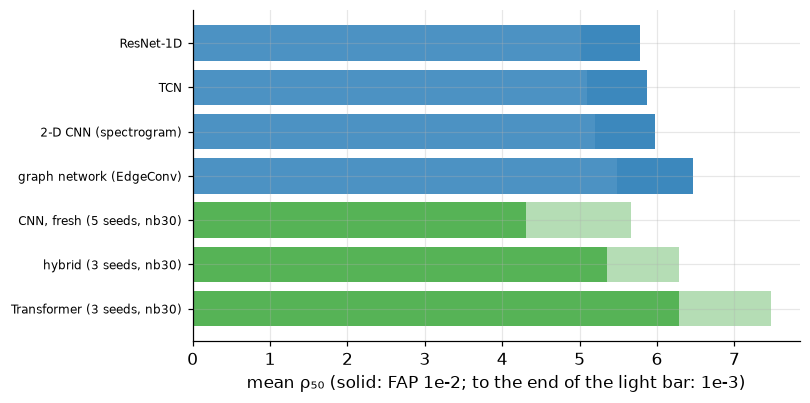

In [5]:
print("per morphology, FAP 1e-2:"); display(R[R.FAP == 1e-2].set_index("model")[["sg", "pulse", "chirp", "mean_rho50", "err"]].round(2))
fig, ax = plt.subplots(figsize=(7.5, 3.8)); T2 = pd.concat([T, ref]); ax.barh(range(len(T2)), T2["FAP 1e-2"], color=["C0"] * len(T) + ["C2"] * 3, alpha=.8); ax.barh(range(len(T2)), T2["FAP 1e-3"] - T2["FAP 1e-2"], left=T2["FAP 1e-2"], color=["C0"] * len(T) + ["C2"] * 3, alpha=.35)
ax.set_yticks(range(len(T2))); ax.set_yticklabels(T2.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("mean ρ₅₀ (solid: FAP 1e-2; to the end of the light bar: 1e-3)"); fig.tight_layout(); g.savefig(fig, "fig34_architectures"); plt.show()
g.save_json(dict(rows=R.to_dict("records"), reference=ref.reset_index().to_dict("records")), "34_summary.json")

## Output and next step

`results/34_summary.json`, `figures/fig34_architectures`, weights `cache/models/v34_*`. Next: the tuning analysis of the Transformer (extension 27) and the generalisation to O2/O3 (extension 41).